# 01. Data exploration and cell selection
Patch-seq, mouse M1 (Scala et al. 2021). Goal: find genes whose expression tracks dendritic morphology.

In [1]:
# Import packages and set seed 

import numpy as np
import pandas as pd
from pathlib import Path
import random

random.seed(12345)

## 1. Load data 
Exon counts (genes x cells), cell metadata and morphology features from the mini-atlas repository. 

In [2]:
# Load the metadata, morphological features and exon counts 

meta  = pd.read_csv("mini-atlas/data/m1_patchseq_meta_data.csv", sep="\t")        # tab-separated
morph = pd.read_csv("mini-atlas/data/m1_patchseq_morph_features.csv", index_col=0)
exon  = pd.read_csv("mini-atlas/data/m1_patchseq_exon_counts.csv.gz", index_col=0)

In [3]:
print("meta :", meta.shape)
print("morph:", morph.shape)
print("exon :", exon.shape)
print(meta.columns.tolist())

meta : (1329, 33)
morph: (646, 63)
exon : (42466, 1329)
['Number', 'Cell', 'Slice', 'Date', 'Sample', 'Mouse', 'Mouse date of birth', 'Mouse age', 'Mouse gender', 'Mouse genotype', 'Targeted layer', 'Inferred layer', 'Cre', 'Exon reads', 'Intron reads', 'Intergenic reads', 'Sequencing batch', 'Number of genes detected', 'RNA family', 'RNA type', 'RNA type confidence', 'RNA type top-3', 'ALM/VISp top-3', 'Length (bp)', 'Yield (pg/µl)', 'User', 'Hold Time (min)', 'Soma depth (µm)', 'Soma depth (4x)', 'Cortical thickness (4x)', 'Cortical thickness (µm)', 'Traced', 'Exclusion reasons']


In [4]:
# Check that cells match across tables 

meta = meta.set_index("Cell") # Makes the cell ID the row labels of the metadata 

# The counts are genes x cells, so cell IDs are the columns
cells_exon = set(exon.columns)

print("morph cells also in exon:", len(set(morph.index) & cells_exon), "/", len(morph))
print("morph cells also in meta:", len(set(morph.index) & set(meta.index)), "/", len(morph))
print()
print("Traced:", meta["Traced"].value_counts(dropna=False).to_dict())
print("RNA family:", meta["RNA family"].value_counts().to_dict())
print("cell class:", morph["cell class"].value_counts().to_dict())
print("n mice:", meta["Mouse"].nunique(), "| n batches:", meta["Sequencing batch"].nunique())
print("exclusion reasons:", meta["Exclusion reasons"].fillna("none").value_counts().to_dict())

morph cells also in exon: 646 / 646
morph cells also in meta: 646 / 646

Traced: {nan: 679, 'y': 646, '?': 3, 'no axon': 1}
RNA family: {'Pvalb': 289, 'Sst': 272, 'IT': 254, 'Vip': 153, 'CT': 106, 'low quality': 97, 'Lamp5': 91, 'ET': 49, 'Sncg': 13, 'NP': 5}
cell class: {'inh': 371, 'exc': 275}
n mice: 266 | n batches: 12
exclusion reasons: {'none': 1322, 'mismatch (FS firing but excitatory RNA)': 3, 'mismatch (MC firing+morphology but excitatory RNA)': 1, 'mismatch (L1 firing+morphology but excitatory RNA)': 1, 'mismatch (FS firing+morphology but excitatory RNA)': 1, 'outside of M1': 1}


## 2. Morphology feature availability 

In [5]:
# Check which morphology features are missing - drop the two text columns, then computes the fraction of NaNs per numeric feature, sorted

num = morph.drop(columns=["cell class", "normalized layer"])
na = num.isna().mean().sort_values(ascending=False)
print(na[na > 0].round(2).to_string())

"apical" branch points                         0.57
dendrite min branch angle                      0.57
"apical" log1p number of outer bifurcations    0.57
"apical" mean bifurcation distance             0.57
"apical" robust height                         0.57
"apical" robust width                          0.57
"apical" std bifurcation distance              0.57
"apical" total length                          0.57
"apical" width                                 0.57
"apical" height                                0.57
dendrite median path angle                     0.57
dendrite above soma                            0.43
dendrite log median tortuosity                 0.43
Log1p fraction of dendrite above axon          0.43
Log1p fraction of axon below dendrite          0.43
Log1p fraction of axon above dendrite          0.43
EMD axon dendrite                              0.43
mean initial segment radius                    0.43
axon robust height                             0.43
axon z-bias 

## 3. Choose the genes-detected cutoff 

In [8]:
# Start with cells that have both morphology and metadata 
cells = morph.index.intersection(meta.index)
print("reconstructed:", len(cells))

# Drop the cell with the wrong reconstruction (flagged in the repo README errata) 
errata = "20171207_sample_1"
print("errata cell present:", errata in cells)
cells = [c for c in cells if c != errata]
print("after errata:", len(cells))

# Subset metadata to the surviving cells 
m = meta.loc[cells]

# metadata exclusions, low-quality / tiny families, low gene detection
m = m[m["Exclusion reasons"].isna()] # Keep cells with no exclusion note from the authors 
print("after exclusion reasons:", len(m))
m = m[~m["RNA family"].isin(["low quality", "NP"])] # ~ means not in, drops low quality cells with poor RNA and NP 
print("after dropping low quality + NP:", len(m))

# Show how many genes have been detected per cell 
print(m["Number of genes detected"].describe().round(0))

reconstructed: 646
errata cell present: True
after errata: 645
after exclusion reasons: 645
after dropping low quality + NP: 634
count      634.0
mean      9961.0
std       3287.0
min       1690.0
25%       8176.0
50%      10134.0
75%      11666.0
max      24833.0
Name: Number of genes detected, dtype: float64


In [10]:
# Which cell classes lack axon / apical features? 
print(pd.crosstab(morph["cell class"], morph["axon total length"].isna(),
                  rownames=["class"], colnames=["axon missing"]))
print(pd.crosstab(morph["cell class"], morph['"apical" total length'].isna(),
                  rownames=["class"], colnames=["apical missing"]))

# Mice and batches in the cells 
print("mice:", m["Mouse"].nunique(), "| batches:", m["Sequencing batch"].nunique(),
      "| median cells/mouse:", m["Mouse"].value_counts().median())

axon missing  False  True 
class                     
exc               0    275
inh             371      0
apical missing  False  True 
class                       
exc               275      0
inh                 0    371
mice: 226 | batches: 12 | median cells/mouse: 3.0


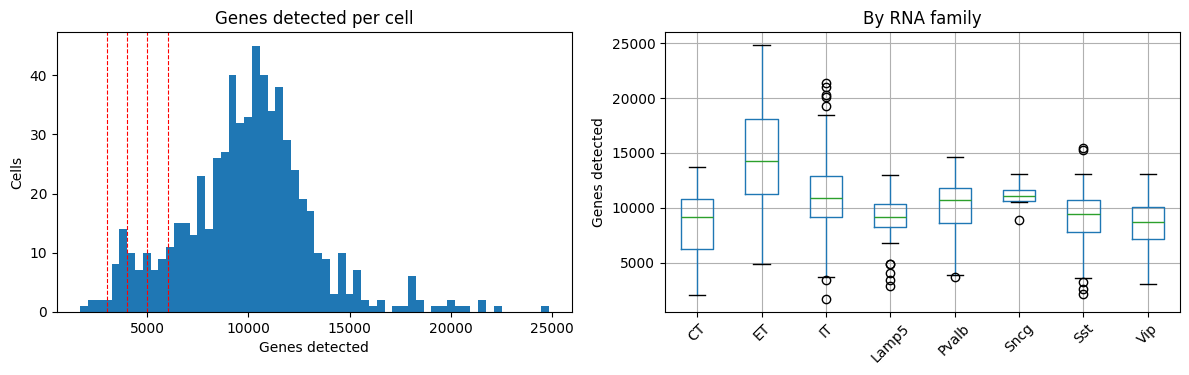

cutoff 3000: removes 5 cells (0.8%) -> {'Sst': 2, 'CT': 1, 'IT': 1, 'Lamp5': 1}
cutoff 4000: removes 29 cells (4.6%) -> {'CT': 11, 'Sst': 6, 'IT': 4, 'Vip': 4, 'Lamp5': 2, 'Pvalb': 2}
cutoff 5000: removes 51 cells (8.0%) -> {'CT': 15, 'Sst': 10, 'IT': 8, 'Pvalb': 7, 'Vip': 5, 'Lamp5': 5, 'ET': 1}
cutoff 6000: removes 75 cells (11.8%) -> {'CT': 19, 'Sst': 15, 'Pvalb': 15, 'IT': 12, 'Vip': 6, 'Lamp5': 5, 'ET': 3}


In [12]:
# Specificy variables 
GENES = "Number of genes detected"
FAMILY = "RNA family"
CUTOFFS = (3000, 4000, 5000, 6000)

n_genes = m[GENES]

fig, (ax_hist, ax_box) = plt.subplots(1, 2, figsize=(12, 4))

# Distribution of genes per cell, with candidate cutoffs
ax_hist.hist(n_genes, bins=60)
for cutoff in CUTOFFS:
    ax_hist.axvline(cutoff, color="red", ls="--", lw=0.8)
ax_hist.set(xlabel="Genes detected", ylabel="Cells", title="Genes detected per cell")

# Spread by RNA family
m.boxplot(column=GENES, by=FAMILY, ax=ax_box, rot=45)
ax_box.set(title="By RNA family", xlabel="", ylabel="Genes detected")
fig.suptitle("")  # remove pandas' automatic "Boxplot grouped by ..." title

fig.tight_layout()
plt.show()

# Cells each cutoff would remove, overall and by family
for cutoff in CUTOFFS:
    removed = m.loc[n_genes < cutoff, FAMILY]
    print(
        f"cutoff {cutoff}: removes {len(removed)} cells ({len(removed) / len(m):.1%}) ->",
        removed.value_counts().to_dict(),
    )

## 4. Define the analysis cells
Once QC plots have been generated, applied appropriate QC metrics that is deemed suitable for the analysis. 

In [16]:
# Apply the genes-detected cutoff - in this case, 4000 
MIN_GENES = 4000
m_final = m[m["Number of genes detected"] >= MIN_GENES].copy()
print("analysis cells:", len(m_final))
print(m_final["RNA family"].value_counts().to_dict())

counts = exon[m_final.index].T

analysis cells: 605
{'IT': 150, 'Pvalb': 143, 'Sst': 102, 'CT': 67, 'Vip': 59, 'Lamp5': 45, 'ET': 33, 'Sncg': 6}


In [17]:
# Normalise: counts per million of the exonic reads, then log2(x + 1)
lib = counts.sum(axis=1)
print("library size (exon reads) min/median/max:", int(lib.min()), int(lib.median()), int(lib.max()))
expr = np.log2(counts.div(lib, axis=0) * 1e6 + 1)

# Detection matrix (which genes have a non-zero count in each cell)
detected = counts > 0

print("counts:", counts.shape)
print("any NaN in expr:", bool(expr.isna().any().any()))
print("median genes detected per cell:", int(detected.sum(axis=1).median()))
print("cells with < 100k exon reads:", int((lib < 100_000).sum()))

library size (exon reads) min/median/max: 10817 1428272 18479190
counts: (605, 42466)
any NaN in expr: False
median genes detected per cell: 7469
cells with < 100k exon reads: 7


## 5. Build covariates for the model 

In [18]:
covars = pd.DataFrame({
    "mouse":        m_final["Mouse"],
    "batch":        m_final["Sequencing batch"].astype(str),
    "rna_family":   m_final["RNA family"],
    "log10_ngenes": np.log10(detected.sum(axis=1)),   # exon-based count from our matrix
    "intron_frac":  m_final["Intron reads"] / (m_final["Intron reads"] + m_final["Exon reads"]),
    "norm_depth":   morph.loc[m_final.index, "normalized depth"],
    "exon_reads":   lib,
})

print("missing values:", covars.isna().sum().to_dict())
print("cells:", len(covars), "| mice:", covars["mouse"].nunique(),
      "| batches:", covars["batch"].nunique(),
      "| median cells/mouse:", covars["mouse"].value_counts().median())

missing values: {'mouse': 0, 'batch': 0, 'rna_family': 0, 'log10_ngenes': 0, 'intron_frac': 0, 'norm_depth': 0, 'exon_reads': 0}
cells: 605 | mice: 223 | batches: 12 | median cells/mouse: 2.0


In [20]:
# Build table of how many cells survive each filtering step 
quality_steps = pd.DataFrame({
    "step": ["reconstructed (morphology + metadata)", "minus errata cell",
             "minus metadata exclusions", "minus low-quality / NP families",
             "genes detected >= 4000"],
    "n_cells": [646, 645, 645, 634, len(m_final)]}) 

quality_steps

,step,n_cells
0,reconstructed (morphology + metadata),646
1,minus errata cell,645
2,minus metadata exclusions,645
3,minus low-quality / NP families,634
4,genes detected >= 4000,605


In [23]:
# Create directory for results 
from pathlib import Path
OUT = Path("results/QC"); OUT.mkdir(parents=True, exist_ok=True)

# Save results 
expr.to_csv(OUT / "expr_log2cpm.csv.gz") # Without gz, it is slow to write 
detected.to_csv(OUT / "detected.csv.gz")
covars.to_csv(OUT / "covars.csv")
quality_steps.to_csv(OUT / "cell_flow.csv", index=False) 
print(sorted(p.name for p in OUT.iterdir()))

['cell_flow.csv', 'covars.csv', 'detected.csv.gz', 'expr_log2cpm.csv.gz']


In [14]:
# meta_ng = m["Number of genes detected"]
# exon_ng = detected.sum(axis=1)
# print("correlation (metadata vs exon-only):", round(np.corrcoef(meta_ng, exon_ng)[0, 1], 3))
# print("exon-only / metadata ratio, median:", round((exon_ng / meta_ng).median(), 2))

correlation (metadata vs exon-only): 0.942
exon-only / metadata ratio, median: 0.74
